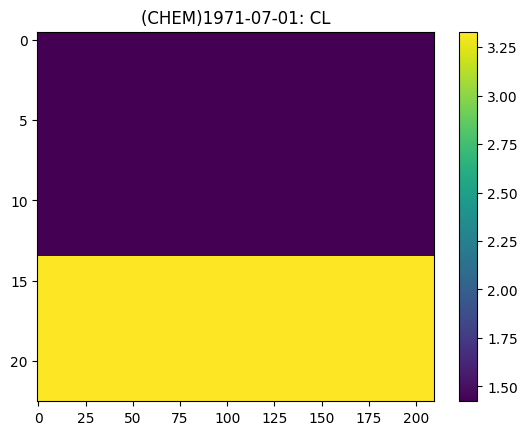

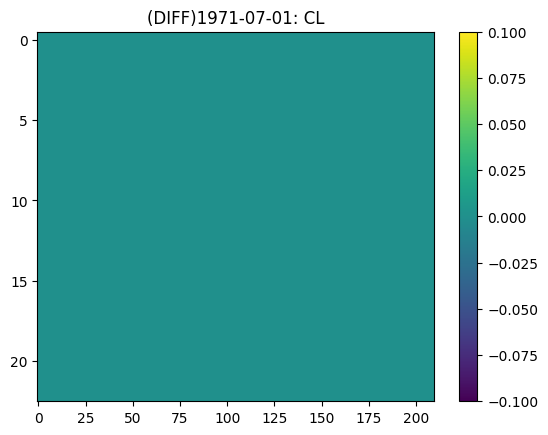

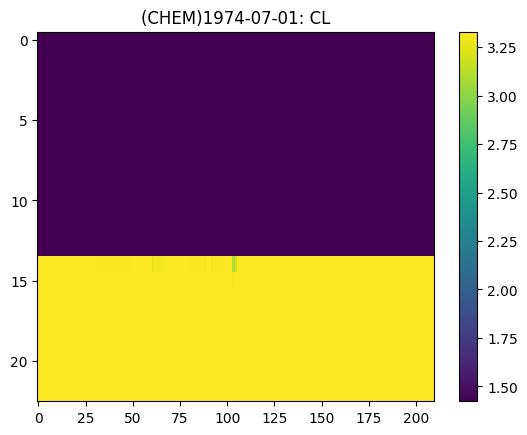

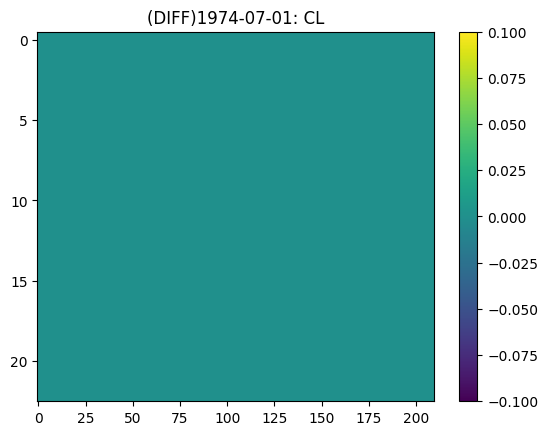

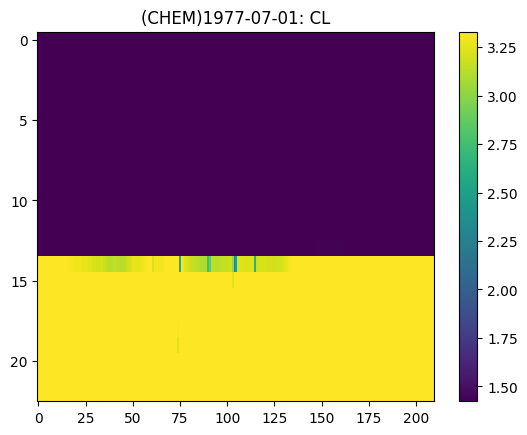

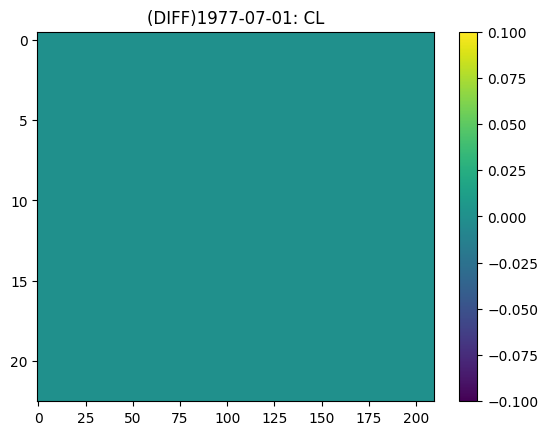

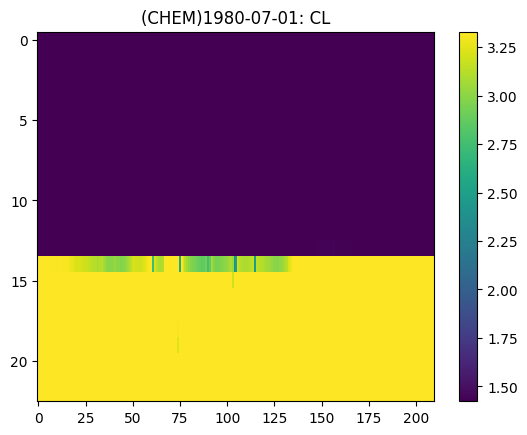

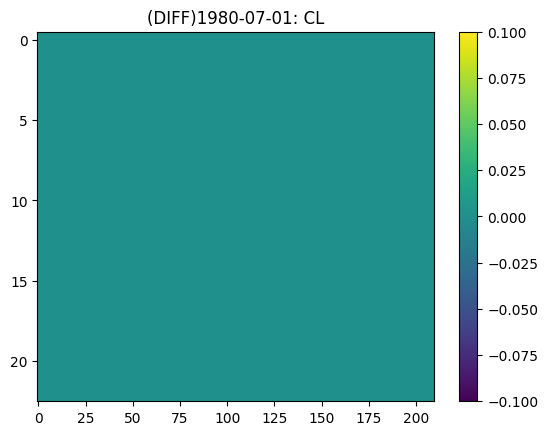

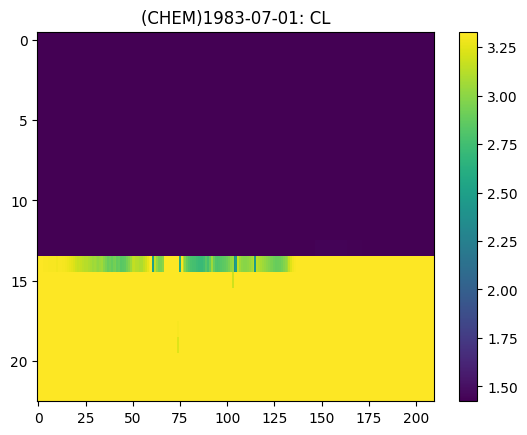

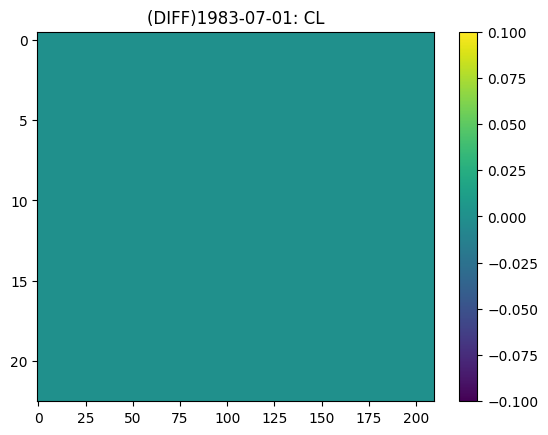

KeyboardInterrupt: 

In [8]:
# Plot 2D-slices of the reservoir

from IORlib.ECL import UNRST_file
from pathlib import Path
import matplotlib.pyplot as pl

home = Path.home()
shared = Path('/home/shared/owner')
#root = shared/'CoP_files/input/IORSIM_BASECASE/IORSIM_BASECASE_INPUT'
root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
chem = UNRST_file(str(root)+'_CHEM')
nochem = UNRST_file(str(root))
pl.close('all')
species = ('CL',)# 'CA')
for chem_cell, no_cell in zip(chem.cellarray(*species, step=36), nochem.cellarray(*species, step=36)):
    #print(str(cell.dates[0]).split()[0], f'CL: {cell.cl.min():.5f}, {cell.cl.max():.5f}')
    date = str(chem_cell.dates[0]).split()[0]
    for var in species:
        name = var.lower()
        pl.figure()
        pl.title(f'(CHEM){date}: {var}')
        pl.imshow(getattr(chem_cell, name)[0,:,100,:].T, interpolation='nearest' , aspect='auto')
        pl.colorbar()
        pl.figure()
        pl.title(f'(DIFF){date}: {var}')
        pl.imshow((getattr(chem_cell, name)-getattr(no_cell, name))[0,:,100,:].T, interpolation='nearest' , aspect='auto')
        pl.colorbar()
    pl.show()

In [ ]:
from IORlib.ECL import UNRST_file, IX_input, SMSPEC_file, EGRID_file, INIT_file
from pathlib import Path
from itertools import repeat
from struct import unpack
from IORlib.utils import batched, ceildiv
from operator import itemgetter
import matplotlib.pyplot as pl

%matplotlib widget

def figures(*keywords):
    # Create figure and axes
    nplots = len(keywords)
    ncols = 1
    nrows = ceildiv(nplots, ncols)
    fig = pl.figure(figsize=(8*ncols, 4*nrows))
    axes = {key:fig.add_subplot(nrows, ncols, i+1) for i,key in enumerate(keywords)}
    fig.subplots_adjust(hspace=0.5, wspace=0.25)
    return axes


def plotdata(cases, cell, *keywords, labels=None):
    # Create figures
    figs = figures(*keywords)
    # Set title
    for key, fig in figs.items():
        fig.set_title(f'{key} for cell {cell}')
    # Plot
    labels = labels or list(repeat(None, len(cases)))
    for case, lbl in zip(cases, labels):
        dates, data = UNRST_file(case).celldata(cell, *keywords)
        for i, key in enumerate(keywords):
            figs[key].plot(dates, data[i], '-o', ms=5, mfc='None', label=lbl, alpha=0.5)
    # Add legend
    for fig in figs.values():
        fig.legend()


In [ ]:
cop_in = Path('/home/shared/owner/CoP_files/input')
cop_out = Path('/home/shared/owner/CoP_files/output')
cases = [Path(f"{cop_in/'IORSIM_BASECASE'}{ext}/IORSIM_BASECASE_INPUT") for ext in ('', '_ITER', '_ITER2', '_ITER3')]
#cases.extend([Path(f"{cop_out}/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022")])
cell = (92, 96, 14)
#figs = plotdata(cases, cell, 'FLRWATJ+', 'CL', labels=('base', 'iter1', 'iter2', 'iter3'))
#print(cases)
figs = figures(*cases)
for case, fig in figs.items():
    unrst = UNRST_file(case)
    high, low = zip(*((max(cl), min(cl)) for cl in unrst.blockdata('CL')))
    fig.set_title(f'max, min Chlorine: {case.parent.name}')
    dates = list(unrst.dates())
    fig.plot(dates, high, 'r-o', dates, low, 'b-o', ms=5, mfc='None', alpha=0.7)
    #fig.legend('Max Cl', 'Min Cl')
    #break